# Salary vs. years of experience: the original capstone analysis (reconstructed)

**RECONSTRUCTION.** The original `.ipynb` from my Year Up CIS 304 capstone (November 2025) was lost
with the Year Up Microsoft account. The code below was recovered line by line from the IPython
history on the same laptop (sessions from Nov 11 and 12, 2025). It reproduces the figures on the
capstone slides exactly: R² 0.957, slope 9,449.96, intercept 25,792.20.

What changed from the recovered code, and nothing else:

- The data path points to `../original/Salary_Data.csv` instead of `./Data-File/Salary_Data.csv`.
- Two spelling fixes in chart labels ("Salery" became "Salary").
- One `plt.savefig` line so the README can show the chart.
- The closing `input()` prompts are replaced with fixed example values so the notebook runs
  unattended. The interactive version lives on as a proper CLI in `../improvements/predict.py`.

The order of steps and the plotting choices are as they were. For the extended analysis
(intervals, residual checks, cross-validation) see `../improvements/salary_analysis.ipynb`.

In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [2]:
filePath = "../original/Salary_Data.csv"   # original: "./Data-File/Salary_Data.csv"
df = pd.read_csv(filePath)
print(df.head(5))

   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0


In [3]:
y = df['Salary']
x = df['YearsExperience']
x_const = sm.add_constant(x)
result = sm.OLS(y, x_const).fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     622.5
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.14e-20
Time:                        16:28:11   Log-Likelihood:                -301.44
No. Observations:                  30   AIC:                             606.9
Df Residuals:                      28   BIC:                             609.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            2.579e+04   2273.053     

In [4]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000


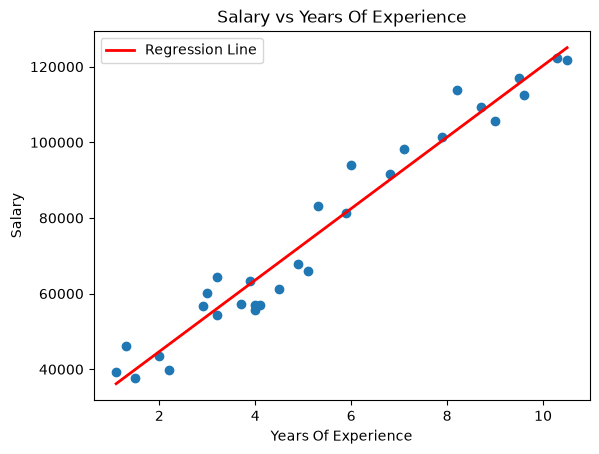

In [5]:
ythat = result.predict(x_const)
plt.scatter(x, y)
plt.plot(x, ythat, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Years Of Experience')
plt.ylabel('Salary')                               # original label read 'Salery'
plt.title('Salary vs Years Of Experience')         # original title read 'Salery vs Years Of Experience'
plt.legend()
plt.savefig('../docs/original_regression_plot.png', dpi=130, bbox_inches='tight')   # added for the README
plt.show()

The capstone ended with a small interactive predictor: type a name and years of experience, get a
salary. `input()` cannot run inside an unattended notebook, so the two prompts are fixed values here.

In [6]:
# Original:
#   name = input("Enter your name: ")
#   years = float(input("Enter years of experience: "))
name = "Example"
years = 5.0
predicted_salary = result.predict([1, years])
print(f"{name}, for {years} years of experience, the predicted salary is: ${predicted_salary[0]:,.2f}")

Example, for 5.0 years of experience, the predicted salary is: $73,042.01
